In [1]:
#Compare model performance

import pandas as pd
import joblib
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [2]:
print("Kernel working")

Kernel working


In [3]:
print("Kernel working")

Kernel working


In [4]:
#Restarted the Kernel

In [5]:
import pandas as pd
import joblib
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [6]:
processed_folder = Path("../dataset/processed")
models_folder = Path("../models")

X_test = pd.read_csv(processed_folder / "X_test.csv")
y_test = pd.read_csv(processed_folder / "y_test.csv").squeeze("columns")

model = joblib.load(models_folder / "random_forest_ciciot2023.pkl")

print("Model and test data loaded successfully.")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Model and test data loaded successfully.
X_test: (108986, 39)
y_test: (108986,)


In [7]:
y_pred = model.predict(X_test)

print("Predictions completed.")
print("Number of predictions:", len(y_pred))

Predictions completed.
Number of predictions: 108986


In [8]:
accuracy = accuracy_score(y_test, y_pred)

print("=== MODEL ACCURACY ===")
print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy (%): {accuracy * 100:.2f}%")

=== MODEL ACCURACY ===
Accuracy: 0.7561
Accuracy (%): 75.61%


In [9]:
print("=== CLASSIFICATION REPORT ===\n")

print(
    classification_report(
        y_test,
        y_pred,
        digits=4,
        zero_division=0
    )
)


=== CLASSIFICATION REPORT ===

                         precision    recall  f1-score   support

       BACKDOOR_MALWARE     0.0000    0.0000    0.0000         8
                 BENIGN     0.7560    0.9073    0.8248      3313
       BROWSERHIJACKING     0.2500    0.0588    0.0952        17
       COMMANDINJECTION     1.0000    0.2000    0.3333        15
 DDOS-ACK_FRAGMENTATION     0.9861    0.9884    0.9872       861
        DDOS-HTTP_FLOOD     0.7013    0.6506    0.6750        83
        DDOS-ICMP_FLOOD     0.9992    0.9986    0.9989     13340
DDOS-ICMP_FRAGMENTATION     0.9758    0.9823    0.9791      1356
      DDOS-PSHACK_FLOOD     0.9992    0.9991    0.9991      9578
       DDOS-RSTFINFLOOD     0.9994    0.9988    0.9991      8817
         DDOS-SLOWLORIS     0.5981    0.9014    0.7191        71
DDOS-SYNONYMOUSIP_FLOOD     0.4457    0.6807    0.5387      8086
         DDOS-SYN_FLOOD     0.5169    0.3594    0.4240      9527
         DDOS-TCP_FLOOD     0.6775    0.6009    0.6369    

In [10]:
from sklearn.metrics import confusion_matrix

In [11]:
import pandas as pd
import joblib
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# File locations
processed_folder = Path("../dataset/processed")
models_folder = Path("../models")

# Load test data
X_test = pd.read_csv(processed_folder / "X_test.csv")
y_test = pd.read_csv(
    processed_folder / "y_test.csv"
).squeeze("columns")

# Load trained model
model = joblib.load(
    models_folder / "random_forest_ciciot2023.pkl"
)

# Generate predictions
y_pred = model.predict(X_test)

print("Evaluation environment ready.")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print("Predictions:", len(y_pred))

Evaluation environment ready.
X_test: (108986, 39)
y_test: (108986,)
Predictions: 108986


In [12]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion matrix generated successfully.")
print("Matrix shape:", cm.shape)

Confusion matrix generated successfully.
Matrix shape: (34, 34)


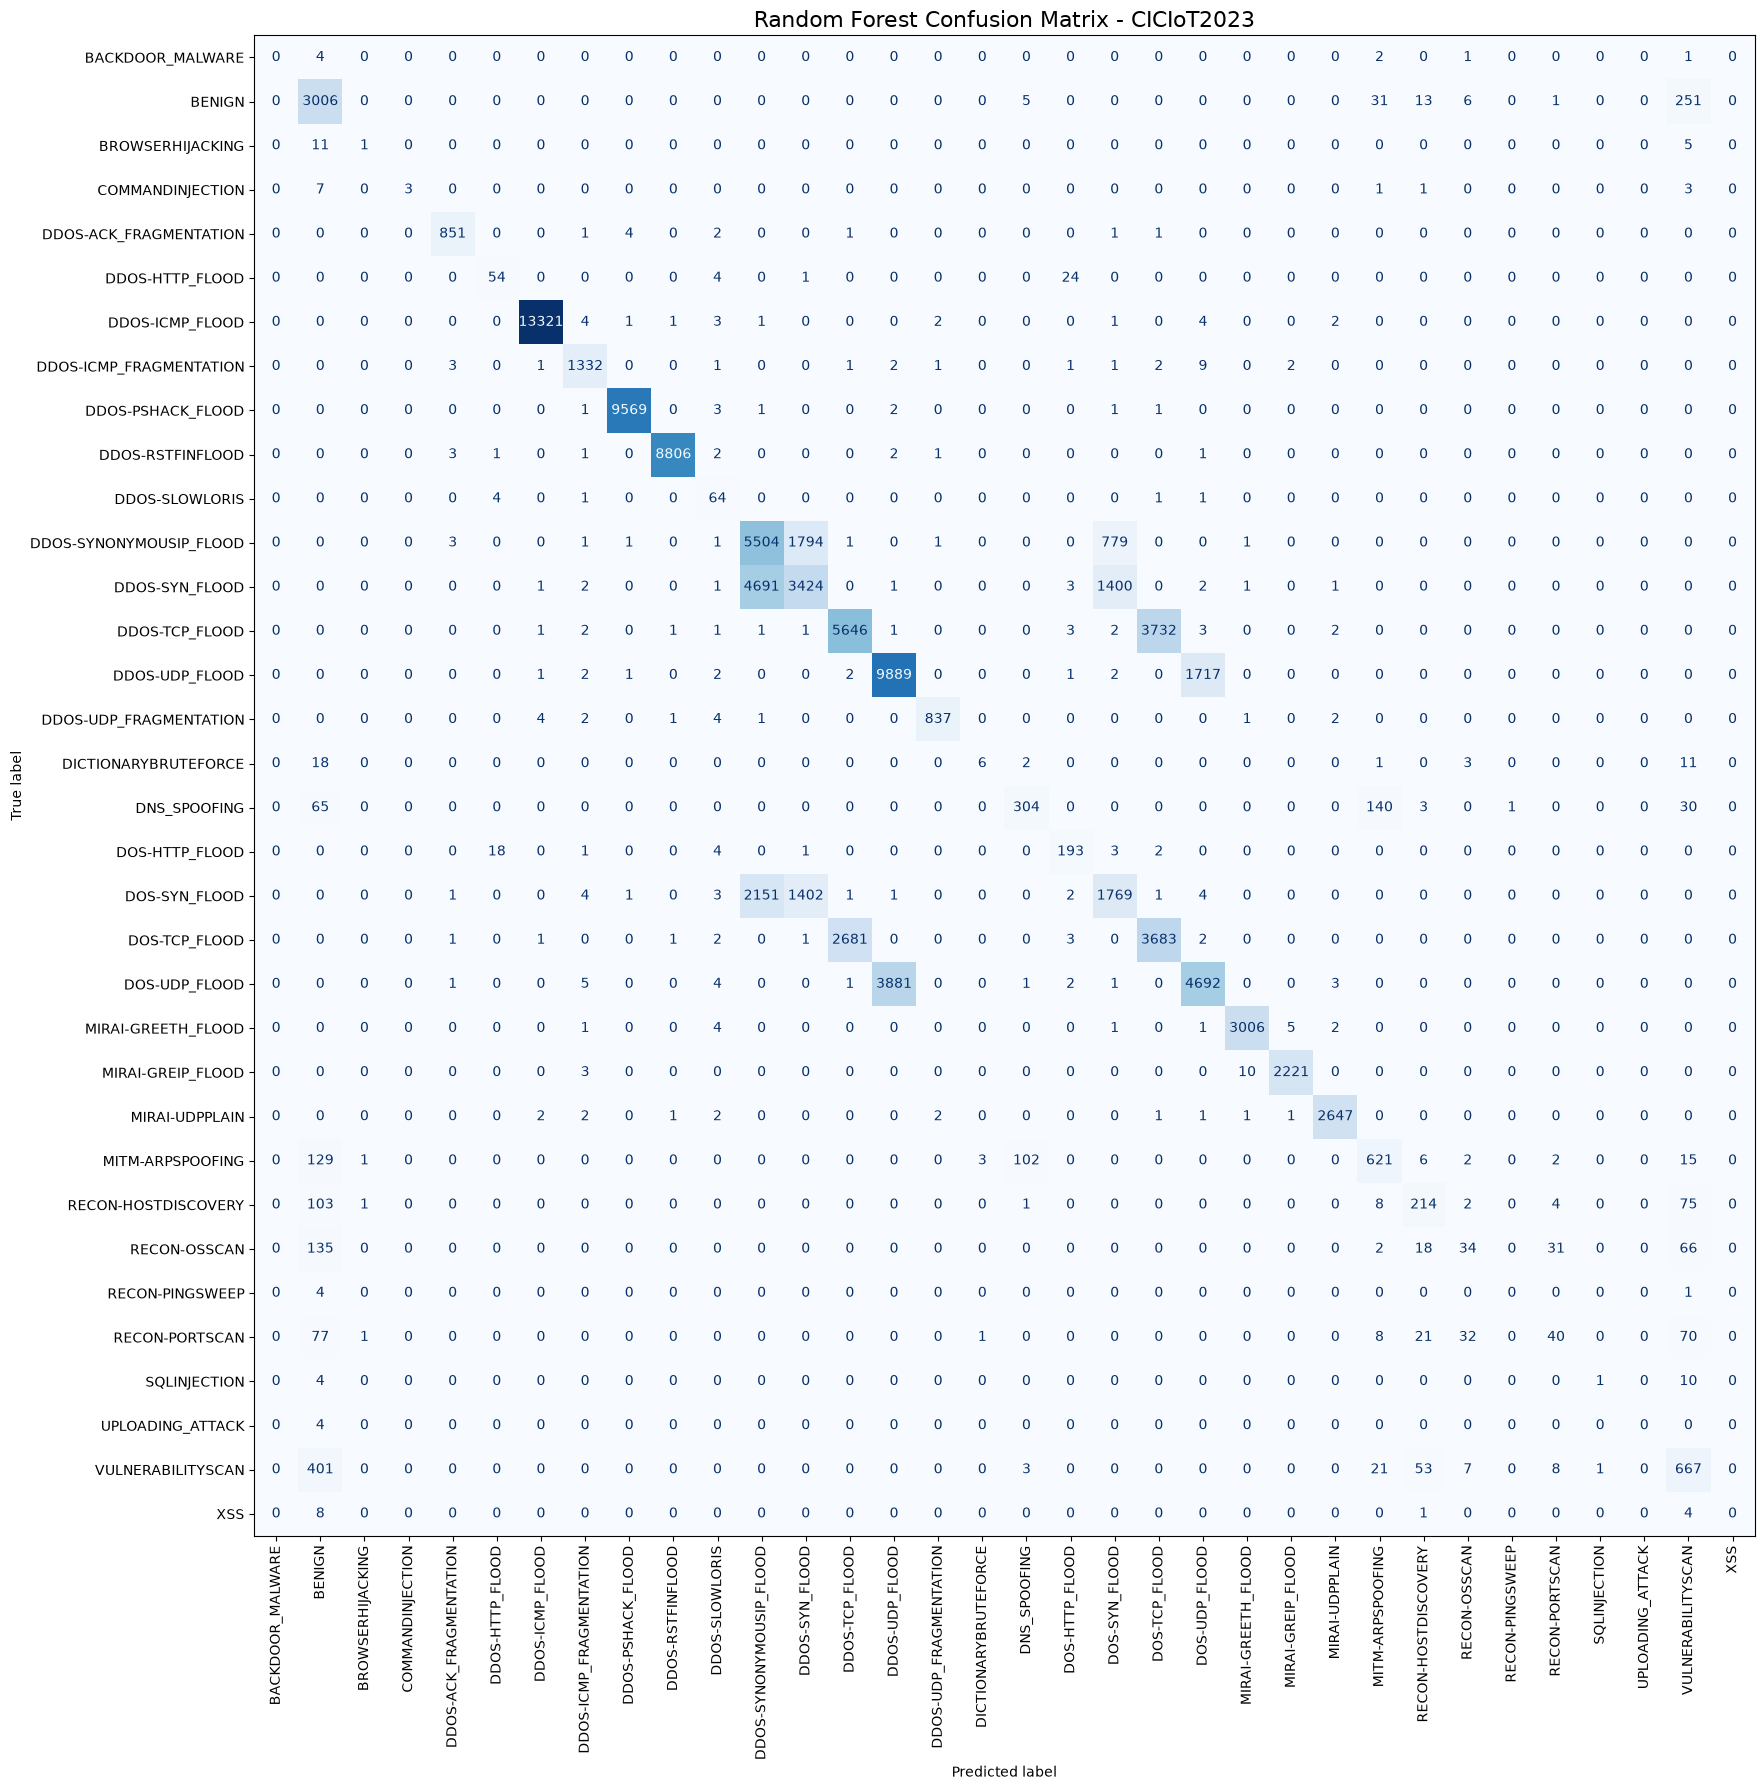

In [13]:
# Import Matplotlib for creating the visualization
import matplotlib.pyplot as plt

# Import ConfusionMatrixDisplay to display the confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay


# Create a large figure because our model contains 34 classes
fig, ax = plt.subplots(figsize=(18, 18))


# Create the confusion matrix display
# cm contains the confusion matrix values calculated earlier
# model.classes_ contains the names of all 34 attack/benign classes
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)


# Plot the confusion matrix
disp.plot(
    ax=ax,

    # Use a blue colour scale to make the matrix easier to read
    cmap="Blues",

    # Rotate class names because there are many labels
    xticks_rotation=90,

    # Display the number of predictions inside each matrix cell
    values_format="d",

    # Remove the colour bar to reduce visual clutter
    colorbar=False
)


# Add a descriptive title to the visualization
plt.title(
    "Random Forest Confusion Matrix - CICIoT2023",
    fontsize=16
)


# Automatically adjust spacing so labels are not cut off
plt.tight_layout()


# Display the confusion matrix
plt.show()

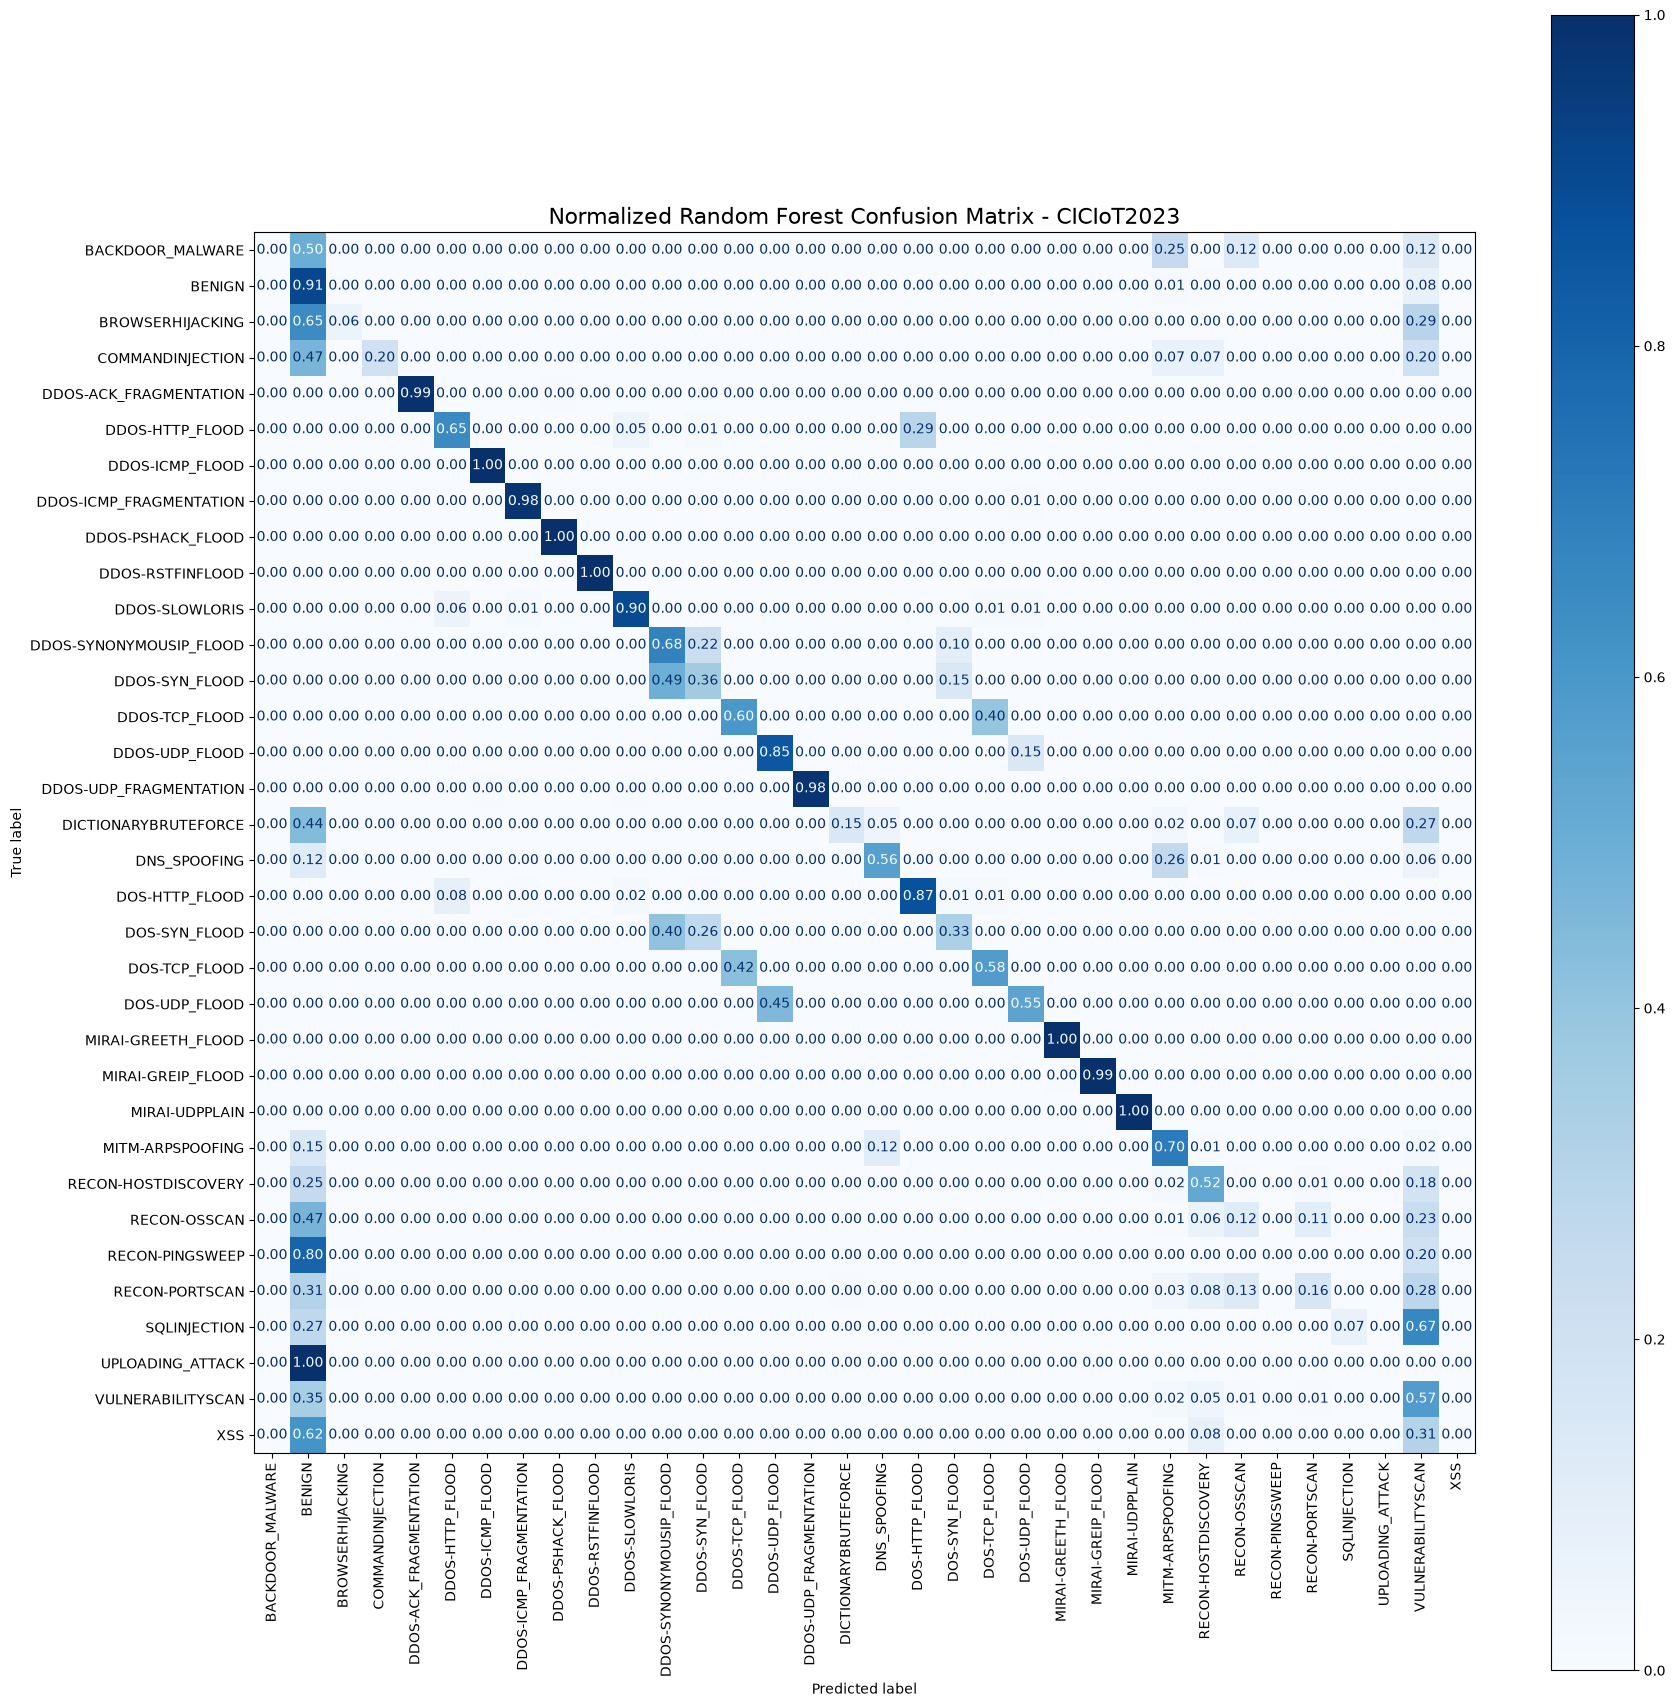

In [14]:
# Import required libraries
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


# Calculate a normalized confusion matrix
# normalize="true" converts each row into proportions based on the actual class
cm_normalized = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_,
    normalize="true"
)


# Create a large figure because the model contains 34 classes
fig, ax = plt.subplots(figsize=(18, 18))


# Create the normalized confusion matrix display
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=model.classes_
)


# Plot the normalized confusion matrix
disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,

    # Show values as decimal proportions
    values_format=".2f",

    colorbar=True
)


# Add a descriptive title
plt.title(
    "Normalized Random Forest Confusion Matrix - CICIoT2023",
    fontsize=16
)


# Adjust spacing so labels are visible
plt.tight_layout()


# Display the visualization
plt.show()

In [15]:
# Import NumPy and Pandas for analysing confusion matrix results
import numpy as np
import pandas as pd


# Get the class names in the same order used by the confusion matrix
class_names = model.classes_


# Create a copy of the original confusion matrix
# We use the raw matrix here because we want actual misclassification counts
cm_errors = cm.copy()


# Remove correct predictions from the analysis
# The diagonal represents correctly classified samples
np.fill_diagonal(cm_errors, 0)


# Store misclassification information
errors = []


# Examine every actual/predicted class combination
for actual_index in range(len(class_names)):
    for predicted_index in range(len(class_names)):

        error_count = cm_errors[actual_index, predicted_index]

        # Only store combinations where a mistake occurred
        if error_count > 0:
            errors.append({
                "Actual Class": class_names[actual_index],
                "Predicted As": class_names[predicted_index],
                "Misclassified Records": error_count
            })


# Convert results into a DataFrame
error_df = pd.DataFrame(errors)


# Sort from the largest number of mistakes to the smallest
error_df = error_df.sort_values(
    by="Misclassified Records",
    ascending=False
)


# Display the 15 largest misclassification pairs
print("=== TOP 15 MODEL MISCLASSIFICATIONS ===")
display(error_df.head(15))

=== TOP 15 MODEL MISCLASSIFICATIONS ===


,Actual Class,Predicted As,Misclassified Records
74,DDOS-SYN_FLOOD,DDOS-SYNONYMOUSIP_FLOOD,4691
147,DOS-UDP_FLOOD,DDOS-UDP_FLOOD,3881
90,DDOS-TCP_FLOOD,DOS-TCP_FLOOD,3732
140,DOS-TCP_FLOOD,DDOS-TCP_FLOOD,2681
128,DOS-SYN_FLOOD,DDOS-SYNONYMOUSIP_FLOOD,2151
66,DDOS-SYNONYMOUSIP_FLOOD,DDOS-SYN_FLOOD,1794
100,DDOS-UDP_FLOOD,DOS-UDP_FLOOD,1717
129,DOS-SYN_FLOOD,DDOS-SYN_FLOOD,1402
77,DDOS-SYN_FLOOD,DOS-SYN_FLOOD,1400
69,DDOS-SYNONYMOUSIP_FLOOD,DOS-SYN_FLOOD,779


In [16]:
# Create a DataFrame containing each feature and its
# importance learned by the trained Random Forest model
feature_importance = pd.DataFrame({
    "Feature": model.feature_names_in_,
    "Importance": model.feature_importances_
})

# Sort features from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the 15 most important network traffic features
print("=== TOP 15 IMPORTANT FEATURES ===")
display(feature_importance.head(15))

=== TOP 15 IMPORTANT FEATURES ===


,Feature,Importance
3,Rate,0.072433
36,IAT,0.061403
0,Header_Length,0.060174
30,Tot sum,0.059993
32,Max,0.054767
33,AVG,0.054424
35,Tot size,0.054168
2,Time_To_Live,0.043967
34,Std,0.042807
38,Variance,0.041440


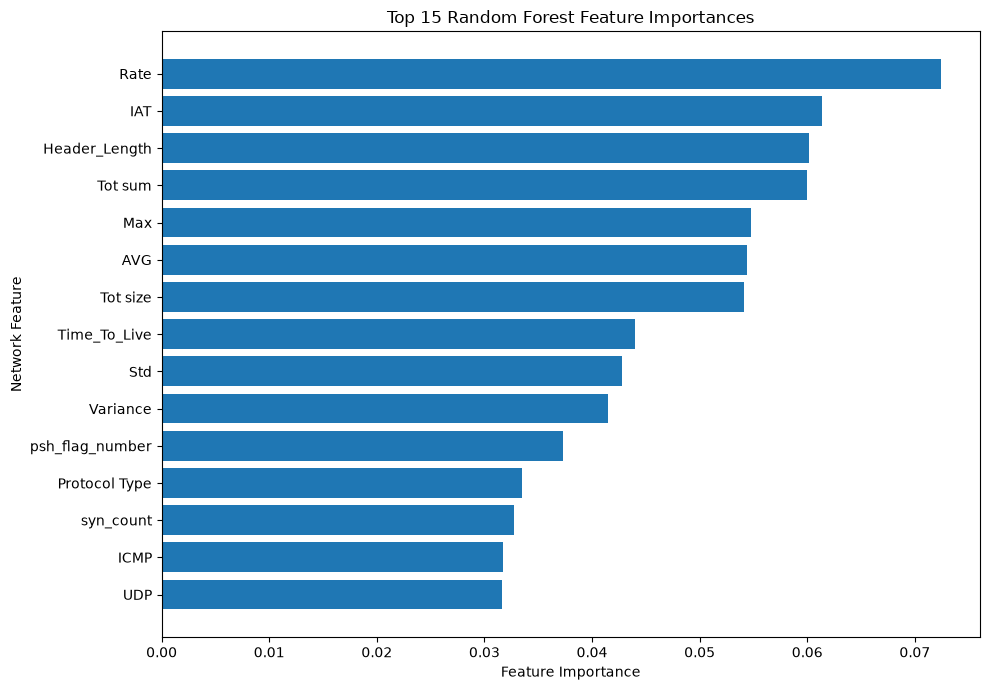

In [17]:
# Select the 15 most important features
top_features = feature_importance.head(15)

# Create the feature-importance chart
plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

# Add chart labels and title
plt.xlabel("Feature Importance")
plt.ylabel("Network Feature")
plt.title("Top 15 Random Forest Feature Importances")

# Adjust layout so feature names are visible
plt.tight_layout()

# Display the chart
plt.show()

In [18]:
# Import NumPy and Pandas for analysing confusion matrix results
import numpy as np
import pandas as pd

# Get the class names in the same order used by the confusion matrix
class_names = model.classes_

# Create a copy of the confusion matrix
cm_errors = cm.copy()

# Remove correct predictions from the analysis
# The diagonal contains correctly classified records
np.fill_diagonal(cm_errors, 0)

# Create a list to store the classification errors
errors = []

# Check every actual and predicted class combination
for actual_index in range(len(class_names)):
    for predicted_index in range(len(class_names)):

        error_count = cm_errors[actual_index, predicted_index]

        # Store only combinations where misclassification occurred
        if error_count > 0:
            errors.append({
                "Actual Class": class_names[actual_index],
                "Predicted As": class_names[predicted_index],
                "Misclassified Records": error_count
            })

# Convert the results into a DataFrame
error_df = pd.DataFrame(errors)

# Sort the errors from highest to lowest
error_df = error_df.sort_values(
    by="Misclassified Records",
    ascending=False
)

# Display the 15 largest model errors
print("=== TOP 15 MODEL MISCLASSIFICATIONS ===")
display(error_df.head(15))

=== TOP 15 MODEL MISCLASSIFICATIONS ===


,Actual Class,Predicted As,Misclassified Records
74,DDOS-SYN_FLOOD,DDOS-SYNONYMOUSIP_FLOOD,4691
147,DOS-UDP_FLOOD,DDOS-UDP_FLOOD,3881
90,DDOS-TCP_FLOOD,DOS-TCP_FLOOD,3732
140,DOS-TCP_FLOOD,DDOS-TCP_FLOOD,2681
128,DOS-SYN_FLOOD,DDOS-SYNONYMOUSIP_FLOOD,2151
66,DDOS-SYNONYMOUSIP_FLOOD,DDOS-SYN_FLOOD,1794
100,DDOS-UDP_FLOOD,DOS-UDP_FLOOD,1717
129,DOS-SYN_FLOOD,DDOS-SYN_FLOOD,1402
77,DDOS-SYN_FLOOD,DOS-SYN_FLOOD,1400
69,DDOS-SYNONYMOUSIP_FLOOD,DOS-SYN_FLOOD,779


In [21]:
# Load the saved improved Random Forest model
# if it has not already been loaded
import joblib
from pathlib import Path

models_folder = Path("../models")

improved_model = joblib.load(
    models_folder / "random_forest_improved_ciciot2023.pkl"
)

print("Improved model loaded successfully.")

Improved model loaded successfully.


In [22]:
# Generate predictions using the improved model
# on the same test dataset used for the baseline model
improved_y_pred = improved_model.predict(X_test)

print("Improved model predictions completed.")
print("Number of predictions:", len(improved_y_pred))

Improved model predictions completed.
Number of predictions: 108986


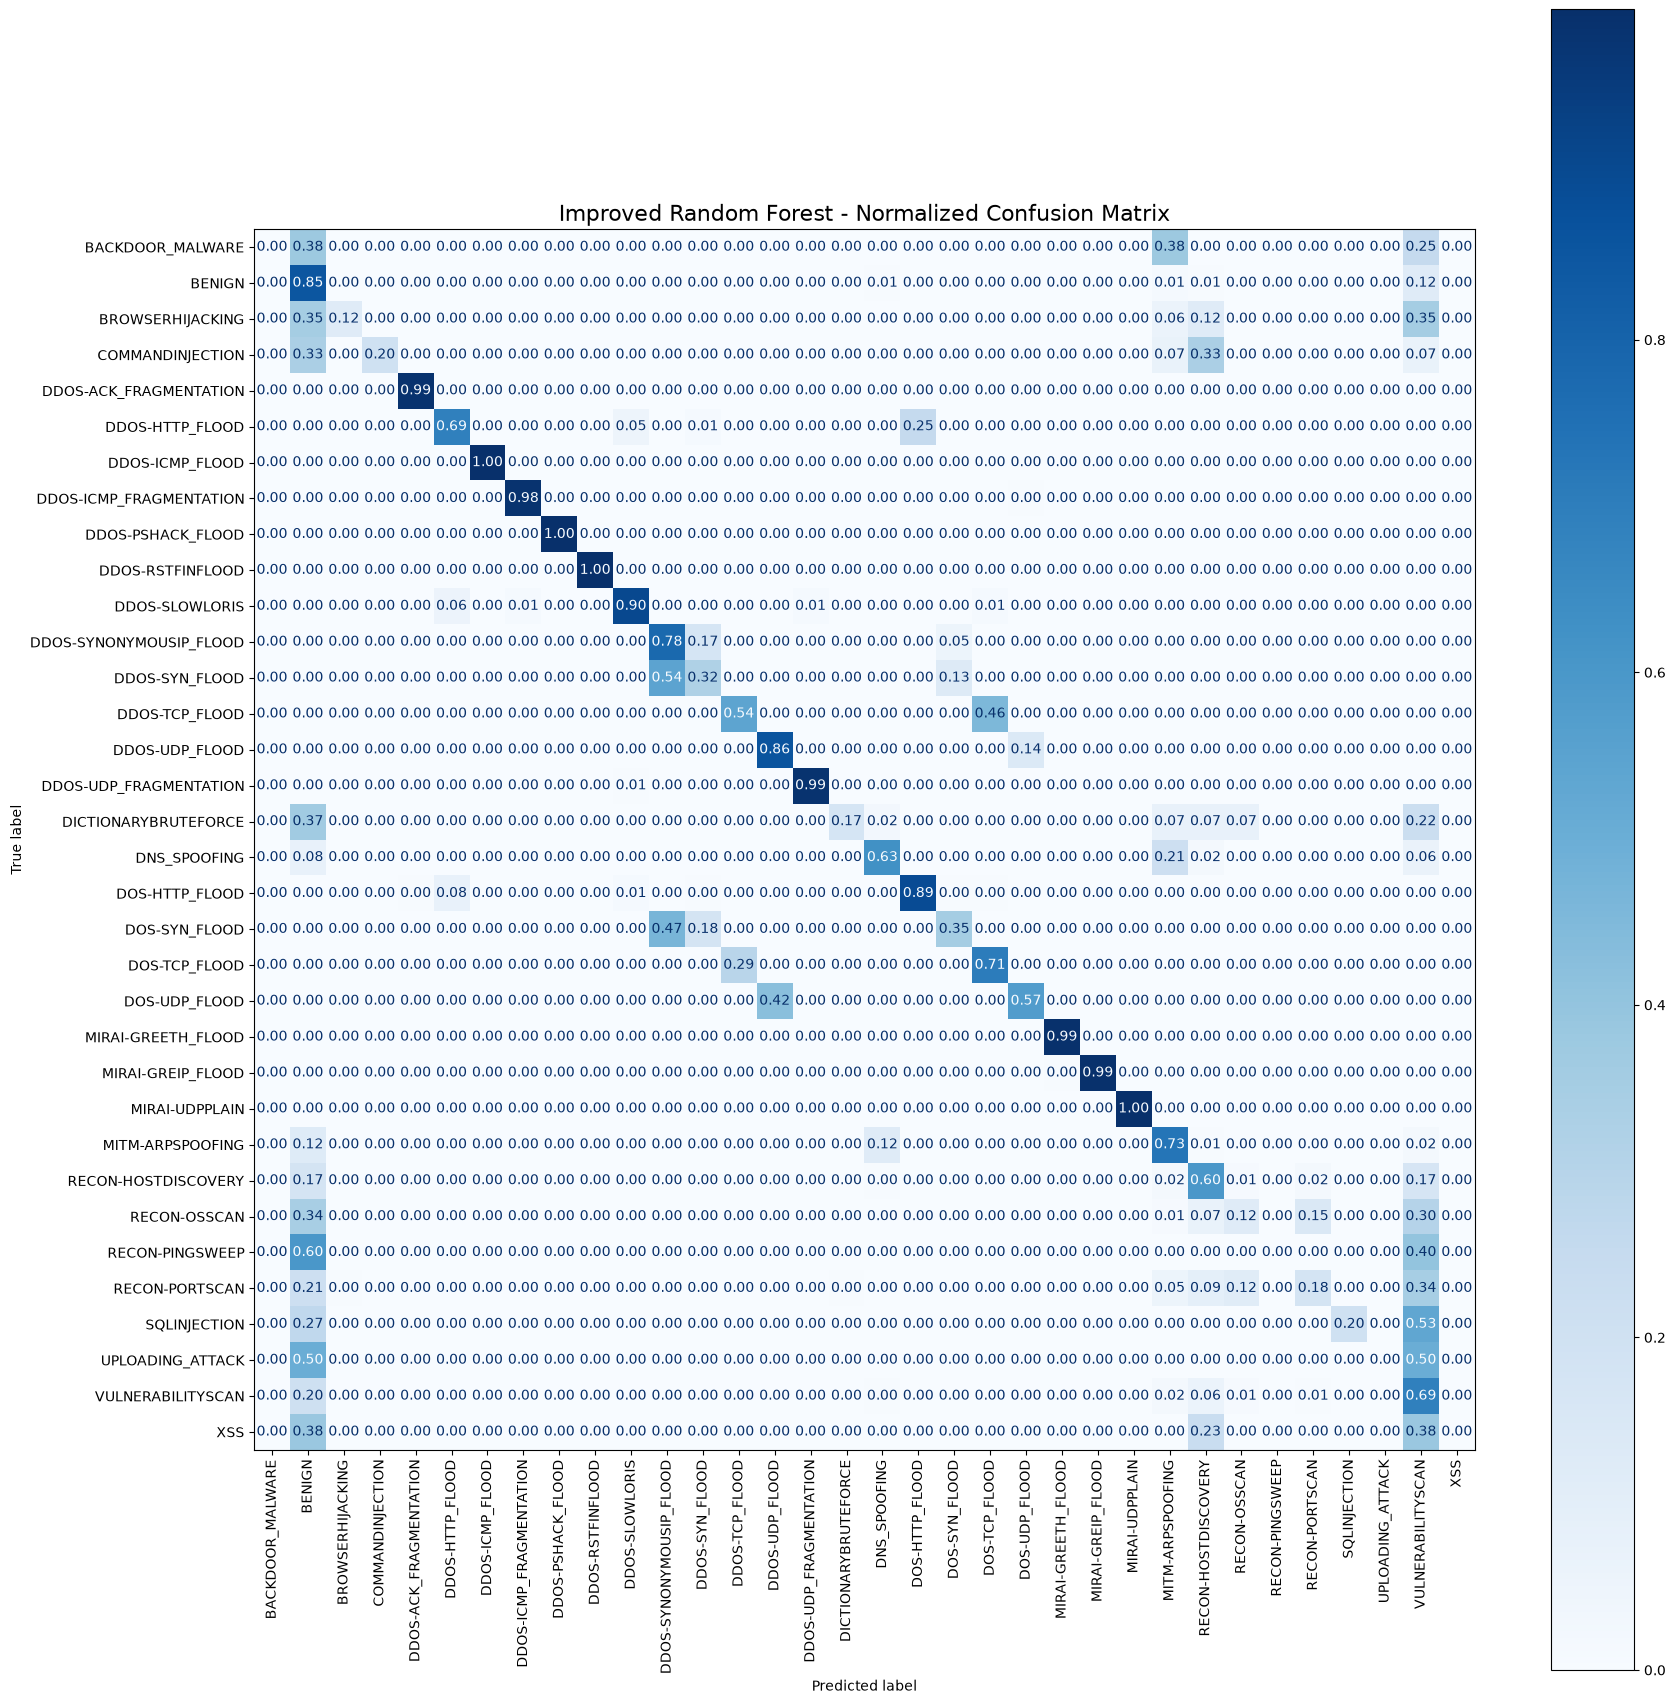

In [23]:


# Import the required confusion matrix tools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


# Generate a normalized confusion matrix for the improved model
# normalize="true" shows the proportion of each actual class
improved_cm = confusion_matrix(
    y_test,
    improved_y_pred,
    labels=improved_model.classes_,
    normalize="true"
)


# Create a large figure because there are 34 classes
fig, ax = plt.subplots(figsize=(18, 18))


# Create the confusion matrix display
disp = ConfusionMatrixDisplay(
    confusion_matrix=improved_cm,
    display_labels=improved_model.classes_
)


# Plot the normalized confusion matrix
disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    values_format=".2f",
    colorbar=True
)


# Add a title
plt.title(
    "Improved Random Forest - Normalized Confusion Matrix",
    fontsize=16
)


# Prevent labels from being cut off
plt.tight_layout()


# Display the chart
plt.show()

In [24]:
# Import NumPy and Pandas for analysing model errors
import numpy as np
import pandas as pd


# Generate the RAW confusion matrix for the improved model
# We use raw counts here instead of normalized percentages
improved_cm_raw = confusion_matrix(
    y_test,
    improved_y_pred,
    labels=improved_model.classes_
)


# Get all class names in the correct order
class_names = improved_model.classes_


# Copy the confusion matrix so the original is not changed
improved_errors_matrix = improved_cm_raw.copy()


# Remove correct predictions
# Diagonal values represent correctly classified records
np.fill_diagonal(improved_errors_matrix, 0)


# Create a list to store misclassification information
improved_errors = []


# Examine every actual/predicted class combination
for actual_index in range(len(class_names)):
    for predicted_index in range(len(class_names)):

        error_count = improved_errors_matrix[
            actual_index,
            predicted_index
        ]

        # Store only combinations where errors occurred
        if error_count > 0:
            improved_errors.append({
                "Actual Class": class_names[actual_index],
                "Predicted As": class_names[predicted_index],
                "Misclassified Records": error_count
            })


# Convert the results into a DataFrame
improved_error_df = pd.DataFrame(improved_errors)


# Sort from the largest error to the smallest
improved_error_df = improved_error_df.sort_values(
    by="Misclassified Records",
    ascending=False
)


# Display the 15 largest errors
print("=== TOP 15 IMPROVED MODEL MISCLASSIFICATIONS ===")
display(improved_error_df.head(15))

=== TOP 15 IMPROVED MODEL MISCLASSIFICATIONS ===


,Actual Class,Predicted As,Misclassified Records
73,DDOS-SYN_FLOOD,DDOS-SYNONYMOUSIP_FLOOD,5190
84,DDOS-TCP_FLOOD,DOS-TCP_FLOOD,4288
137,DOS-UDP_FLOOD,DDOS-UDP_FLOOD,3639
123,DOS-SYN_FLOOD,DDOS-SYNONYMOUSIP_FLOOD,2484
132,DOS-TCP_FLOOD,DDOS-TCP_FLOOD,1865
92,DDOS-UDP_FLOOD,DOS-UDP_FLOOD,1606
67,DDOS-SYNONYMOUSIP_FLOOD,DDOS-SYN_FLOOD,1366
75,DDOS-SYN_FLOOD,DOS-SYN_FLOOD,1256
124,DOS-SYN_FLOOD,DDOS-SYN_FLOOD,945
68,DDOS-SYNONYMOUSIP_FLOOD,DOS-SYN_FLOOD,417
